In [438]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import set_config
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, MinMaxScaler, OneHotEncoder,
                                   OrdinalEncoder, StandardScaler)

#Subimos el archivo de la carpeta data
set_config(transform_output="pandas")

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

titanic =  pd.read_csv(DATA_DIR/"titanic.csv")
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [439]:
titanic.head(5)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [440]:
titanic.tail(5)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [441]:
titanic.info()
titanic.describe()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [442]:
print(titanic.duplicated().mean()*100)
for col in ["survived", "pclass", "age","sibsp","parch","fare","embarked","class","who","adult_male","deck","embark_town","alive","alone"]:
    print(titanic[col].value_counts(dropna=False), "\n")

12.008978675645341
survived
0    549
1    342
Name: count, dtype: int64 

pclass
3    491
1    216
2    184
Name: count, dtype: int64 

age
NaN      177
24.00     30
22.00     27
18.00     26
28.00     25
        ... 
24.50      1
0.67       1
0.42       1
34.50      1
74.00      1
Name: count, Length: 89, dtype: int64 

sibsp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64 

parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64 

fare
8.0500     43
13.0000    42
7.8958     38
7.7500     34
26.0000    31
           ..
13.8583     1
50.4958     1
5.0000      1
9.8458      1
10.5167     1
Name: count, Length: 248, dtype: int64 

embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64 

class
Third     491
First     216
Second    184
Name: count, dtype: int64 

who
man      537
woman    271
child     83
Name: count, dtype: int64 

adult_male
True     537
False    354
Name: count, dtype

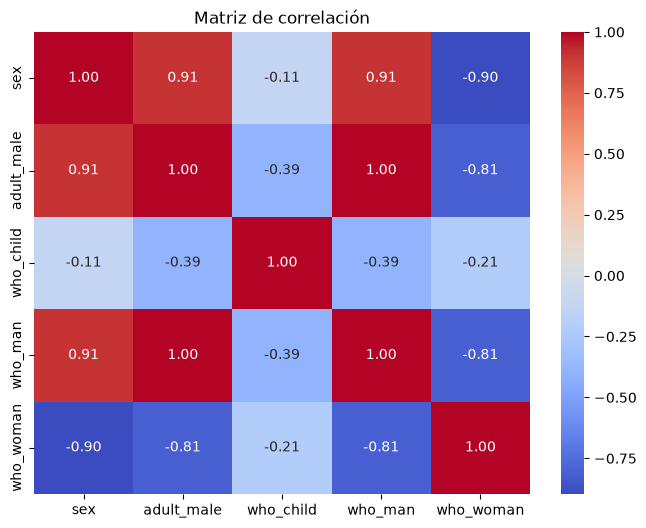

In [443]:
valores = titanic[["sex", "who", "adult_male"]].copy()

valores["sex"] = valores["sex"].map({"male":"1", "female": '0'})

valores["adult_male"] = valores["adult_male"].map({True:"1", False: "0"})

valores = pd.get_dummies(

    valores,

    columns=["who"],

    dtype=int
)

corr = valores.corr()

 

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=ax)

ax.set_title("Matriz de correlación")

plt.show()

## for col in ["survived", "pclass", "age","sibsp","parch","fare","embarked","class","who","adult_male","deck","embark_town","alive","alone"]:

##    print(titanic[col].value_counts(dropna=False), "\n")






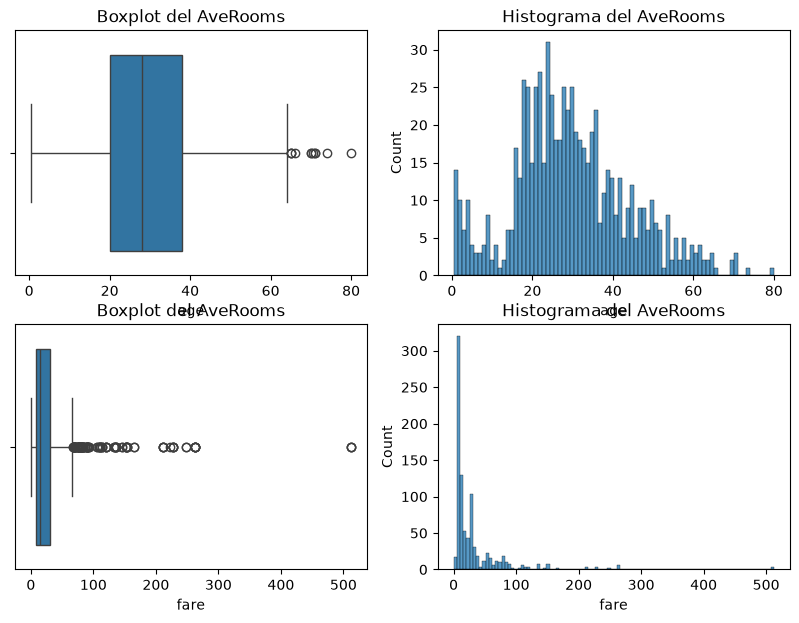

In [444]:


fig1, axes = plt.subplots(2, 2,figsize=(10, 7))
sns.boxplot(x=titanic["age"], ax=axes[0,0])
axes[0,0].set_title("Boxplot del AveRooms")
sns.histplot(x=titanic["age"], bins=80, ax=axes[0,1])
axes[0,1].set_title("Histograma del AveRooms")
sns.boxplot(x=titanic["fare"], ax=axes[1,0])
axes[1,0].set_title("Boxplot del AveRooms")
sns.histplot(x=titanic["fare"], bins=100, ax=axes[1,1])
axes[1,1].set_title("Histograma del AveRooms")
plt.show()


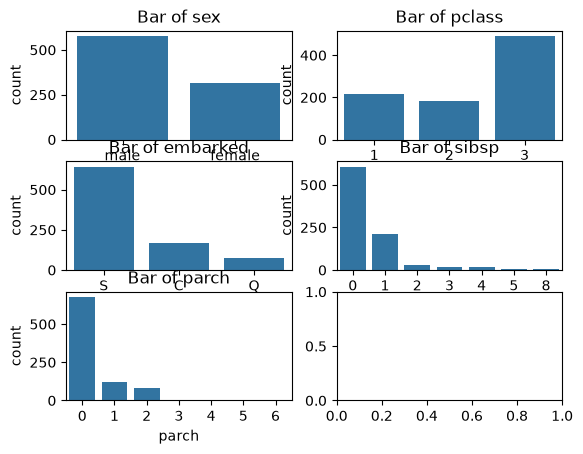

In [445]:


fig, axes = plt.subplots(3, 2)
sns.countplot(data=titanic, x="sex", ax=axes[0,0])
axes[0,0].set_title("Bar of sex")
sns.countplot(data=titanic, x="pclass", ax=axes[0,1])
axes[0,1].set_title("Bar of pclass")
sns.countplot(data=titanic, x="embarked", ax=axes[1,0])
axes[1,0].set_title("Bar of embarked")
sns.countplot(data=titanic, x="sibsp", ax=axes[1,1])
axes[1,1].set_title("Bar of sibsp")
sns.countplot(data=titanic, x="parch", ax=axes[2,0])
axes[2,0].set_title("Bar of parch")
plt.show()

In [446]:
resumen = (titanic.groupby("pclass")["survived"].mean())*100
print(resumen)

pclass
1    62.962963
2    47.282609
3    24.236253
Name: survived, dtype: float64


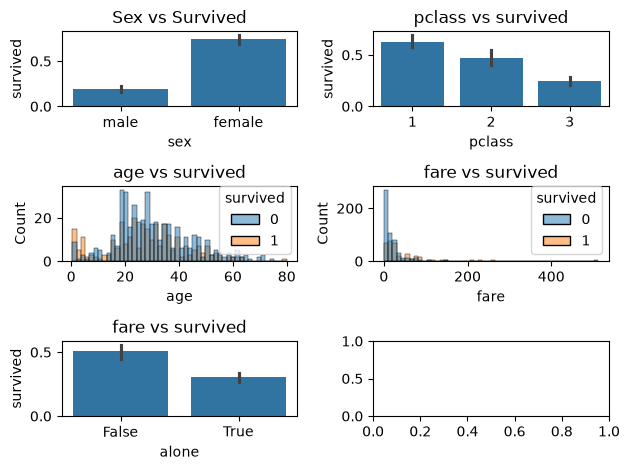

In [447]:
fig, axes = plt.subplots(3, 2)
sns.barplot(data=titanic, x="sex", y="survived", ax=axes[0,0])
axes[0,0].set_title("Sex vs Survived")
sns.barplot(data=titanic, x="pclass", y="survived" ,ax=axes[0,1])
axes[0,1].set_title("pclass vs survived")
sns.histplot(data=titanic, x="age", hue="survived",bins=50,ax=axes[1,0])
axes[1,0].set_title("age vs survived")
sns.histplot(data=titanic, x="fare", hue="survived",bins=50,ax=axes[1,1])
axes[1,1].set_title("fare vs survived")
sns.barplot(data=titanic, x="alone", y="survived",ax=axes[2,0])
axes[2,0].set_title("fare vs survived")
plt.tight_layout()
plt.show()

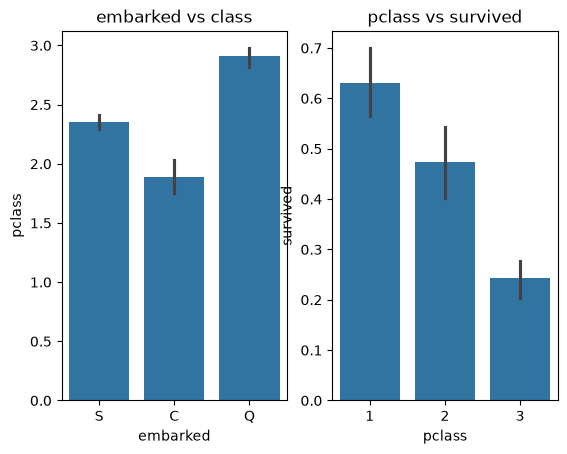

In [448]:
fig,ax = plt.subplots(1,2)
sns.barplot(titanic,y="pclass",x="embarked",ax=ax[0])
ax[0].set_title("embarked vs class")
sns.barplot(titanic, x="pclass",y="survived",ax=ax[1])
ax[1].set_title("pclass vs survived")
plt.show()

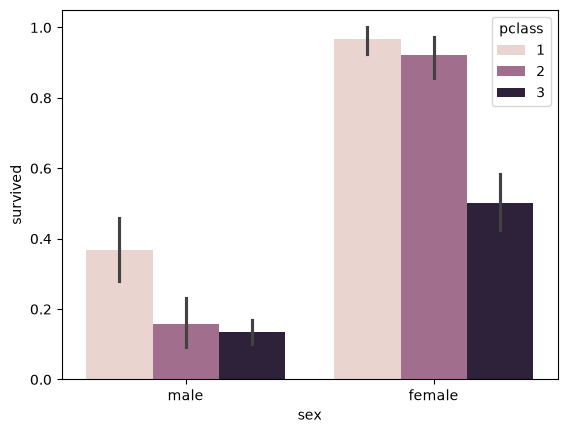

In [449]:
fig, ax = plt.subplots()
sns.barplot(titanic,x="sex",y="survived",hue="pclass",ax=ax)
plt.show()

In [450]:
titanic_copy = titanic.copy()
titanic_copy.head()
#Embarked y embark_town son las mismas columnas
#adult_male esta de mas, no aporta informacion nueva
#alive tambien es una categoria repetiva, tenemos a survived
#pclass y clase tambien son las mismas columnas
titanic_copy = titanic_copy.drop(columns=["embark_town","adult_male","class","alive"])
print(f"total de filas duplicadas: {titanic_copy.duplicated().sum()}")
titanic_copy[titanic_copy.duplicated()].head(10)
titanic_copy = titanic_copy.drop_duplicates()
print(f"total de filas duplicadas: {titanic_copy.duplicated().sum()}")
titanic_copy.head()

total de filas duplicadas: 107
total de filas duplicadas: 0


,survived,pclass,sex,age,sibsp,parch,fare,embarked,who,deck,alone
0,0,3,male,22.0,1,0,7.2500,S,man,NaN,False
1,1,1,female,38.0,1,0,71.2833,C,woman,C,False
2,1,3,female,26.0,0,0,7.9250,S,woman,NaN,True
3,1,1,female,35.0,1,0,53.1000,S,woman,C,False
4,0,3,male,35.0,0,0,8.0500,S,man,NaN,True


In [451]:
titanic_copy.sort_values("fare",ascending=True).head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,who,deck,alone
597,0,3,male,49.0,0,0,0.0,S,man,NaN,True
822,0,1,male,38.0,0,0,0.0,S,man,NaN,True
815,0,1,male,NaN,0,0,0.0,S,man,B,True
806,0,1,male,39.0,0,0,0.0,S,man,A,True
302,0,3,male,19.0,0,0,0.0,S,man,NaN,True


In [452]:
#titanic_copy.info()
print("\n")
print(f"Porcentaje de datos faltantes de la columna 'age': {((titanic_copy["age"].isna().sum()/784)*100).round(2)}%")
print(f"Porcentaje de datos faltantes de la columna 'deck': {((titanic_copy["deck"].isna().sum()/784)*100).round(2)}%")
print(f"Porcentaje de datos faltantes de la columna 'embarked': {((titanic_copy["embarked"].isna().sum()/784)*100).round(2)}%")

#Para age sera mediante la mediana de cada grupo, en este caso la mediana de mujer, la mediana de hombre
#la mediana de niña y la mediana de niño
titanic_copy.groupby(["sex","who"])["age"].mean()
titanic_copy["age"] = titanic_copy["age"].fillna(titanic_copy.groupby(["sex","who"])["age"].transform("median"))
print(f"Llenado de datos: \nPorcentaje de datos faltantes de la columna 'age': {((titanic_copy["age"].isna().sum()/784)*100).round(2)}%")
#Para embarked, como es una columna con categorias se utilizara la moda
titanic_copy["embarked"] = titanic_copy["embarked"].fillna(titanic_copy["embarked"].mode()[0])
print(f"Porcentaje de datos faltantes de la columna 'embarked': {((titanic_copy["embarked"].isna().sum()/784)*100).round(2)}%\n")
#Para la columna deck, es muy poca informacion al respecto, siendo aproximandamente 1/4 de información
#Se opta por eliminarla
titanic_copy =  titanic_copy.drop(columns=["deck"])
print(f"Datos faltanes: {titanic_copy.isna().sum()}")



Porcentaje de datos faltantes de la columna 'age': 13.52%
Porcentaje de datos faltantes de la columna 'deck': 74.23%
Porcentaje de datos faltantes de la columna 'embarked': 0.26%
Llenado de datos: 
Porcentaje de datos faltantes de la columna 'age': 0.0%
Porcentaje de datos faltantes de la columna 'embarked': 0.0%

Datos faltanes: survived    0
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
who         0
alone       0
dtype: int64


In [453]:
#Utilizar el metodo dispercion con |Z|>3 para age, fare, sibsp, parch
z = (titanic_copy[["age","fare","sibsp","parch"]].mean())/titanic_copy[["age","fare","sibsp","parch"]].std()
print(f"Outliers por z-score: {(z.abs()>3).sum()}\n")

#Utilizando el metodo IQR
def limites_iqr(serie, k=1.5):
    """Devuelve los límites inferior y superior según la regla del IQR."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

inf,sup = limites_iqr(titanic_copy["fare"])
print(f"Rangos aceptables: [{inf:,.0f},{sup:,.0f}]")
Outliers_iqr = titanic_copy[(titanic_copy["fare"]<inf) | (titanic_copy["fare"])>sup]
print("Outliers por IQR de fare:", len(Outliers_iqr))

inf,sup = limites_iqr(titanic_copy["age"])
print(f"Rangos aceptables: [{inf:,.0f},{sup:,.0f}]")
Outliers_iqr = titanic_copy[(titanic_copy["age"]<inf) | (titanic_copy["age"])>sup]
print("Outliers por IQR de age:", len(Outliers_iqr))

inf,sup = limites_iqr(titanic_copy["sibsp"])
print(f"Rangos aceptables: [{inf:,.0f},{sup:,.0f}]")
Outliers_iqr = titanic_copy[(titanic_copy["sibsp"]<inf) | (titanic_copy["sibsp"])>sup]
print("Outliers por IQR de sibsp:", len(Outliers_iqr))

inf,sup = limites_iqr(titanic_copy["parch"])
print(f"Rangos aceptables: [{inf:,.0f},{sup:,.0f}]")
Outliers_iqr = titanic_copy[(titanic_copy["parch"]<inf) | (titanic_copy["parch"])>sup]
print("Outliers por IQR de parch:", len(Outliers_iqr))

Outliers por z-score: 0

Rangos aceptables: [-31,73]
Outliers por IQR de fare: 0
Rangos aceptables: [1,57]
Outliers por IQR de age: 0
Rangos aceptables: [-2,2]
Outliers por IQR de sibsp: 0
Rangos aceptables: [-2,2]
Outliers por IQR de parch: 0


In [ ]:
#La mayoria parece que esta dentro del rango pero hay cosas que no llegan a tener mucho sentido
titanic_copy["age"].sort_values(ascending=True) #Edades menores a 1 años?
error_edad = titanic_copy["age"] < 1
print(f"Errores de edad: {error_edad.sum()}")

titanic_copy["fare"].sort_values(ascending=True) #Precios del boleto en 0 libras? arriba de 500 libras?
error_fare = (titanic_copy["fare"] == 0) | (titanic_copy["fare"] > 500)
print(f"Error del precio del boleto: {error_fare.sum()}")

#Para comprobar las columnas sibsp y parch, se ocupara la columna alone
error_sibsp_parch = titanic_copy[(titanic_copy["sibsp"] > 0) & (titanic_copy["parch"] > 0) & (titanic_copy["alone"] == 1)]
print(f"Errores con inconsistencia: {error_sibsp_parch["alone"].sum()}")

titanic_copy["sibsp"].sort_values(ascending=True) #Tener 8 hermanos en un viaje?
error_hermanos = titanic_copy["sibsp"] >= 8
print(f"Errror de hermano: {error_hermanos.sum()}")

Errores de edad: 6
Error del precio del boleto: 13
Errores con inconsistencia: 0
Errror de hermano: 2


In [461]:
titanic_copy = titanic_copy[~error_edad] #Eliminamos los errores de edad
titanic_copy = titanic_copy[~error_fare] #Eliminamos el error de los boletos
titanic_copy = titanic_copy[~error_hermanos] #Eliminamos el error con los hermanos

titanic_copy.sort_values("age",ascending=True)

C:\Users\flavs\AppData\Local\Temp\ipykernel_16156\1751653729.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  titanic_copy = titanic_copy[~error_edad] #Eliminamos los errores de edad
C:\Users\flavs\AppData\Local\Temp\ipykernel_16156\1751653729.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  titanic_copy = titanic_copy[~error_fare] #Eliminamos el error de los boletos
C:\Users\flavs\AppData\Local\Temp\ipykernel_16156\1751653729.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  titanic_copy = titanic_copy[~error_hermanos] #Eliminamos el error con los hermanos


,survived,pclass,sex,age,sibsp,parch,fare,embarked,who,alone
381,1,3,female,1.0,0,2,15.7417,C,child,False
386,0,3,male,1.0,5,2,46.9000,S,child,False
788,1,3,male,1.0,1,2,20.5750,S,child,False
827,1,2,male,1.0,0,2,37.0042,C,child,False
164,0,3,male,1.0,4,1,39.6875,S,child,False
...,...,...,...,...,...,...,...,...,...,...
116,0,3,male,70.5,0,0,7.7500,Q,man,True
96,0,1,male,71.0,0,0,34.6542,C,man,True
493,0,1,male,71.0,0,0,49.5042,C,man,True
851,0,3,male,74.0,0,0,7.7750,S,man,True


In [464]:
titanic_copy.describe()

,survived,pclass,age,sibsp,parch,fare
count,763.000000,763.000000,763.000000,763.000000,763.000000,763.000000
mean,0.410223,2.251638,30.131062,0.509830,0.410223,33.153789
std,0.492197,0.852421,13.628093,0.918372,0.837601,43.082319
min,0.000000,1.000000,1.000000,0.000000,0.000000,4.012500
25%,0.000000,1.000000,22.000000,0.000000,0.000000,8.050000
50%,0.000000,3.000000,30.000000,0.000000,0.000000,16.000000
75%,1.000000,3.000000,36.000000,1.000000,1.000000,33.760400
max,1.000000,3.000000,80.000000,5.000000,6.000000,263.000000


In [463]:
titanic.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [465]:
titanic_copy.info()
titanic.info()

<class 'pandas.DataFrame'>
Index: 763 entries, 0 to 890
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  763 non-null    int64  
 1   pclass    763 non-null    int64  
 2   sex       763 non-null    str    
 3   age       763 non-null    float64
 4   sibsp     763 non-null    int64  
 5   parch     763 non-null    int64  
 6   fare      763 non-null    float64
 7   embarked  763 non-null    str    
 8   who       763 non-null    str    
 9   alone     763 non-null    bool   
dtypes: bool(1), float64(2), int64(4), str(3)
memory usage: 60.4 KB
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-nul